# Cooling of a Square Plate
A concise companion to *PDEs_NLA_BAM_Project.pdf*. Headings follow the report; supporting checks stay in code rather than long explanations.

## 3. Inputs and setup
Unit square, zero boundary temperature, $\kappa=0.1$, $T=1$. The main run uses $m=40$ interior points per direction and $\Delta t=0.005$.

Run **Restart Kernel → Run All**. Requires Python 3.10+, NumPy, SciPy, Matplotlib, pandas, psutil and Jupyter; all figures appear inline, with no input files or figure exports.

In [19]:
import sys, platform, time
import numpy as np
import scipy
from scipy import sparse
from scipy.sparse.linalg import cg as scipy_cg, splu
from scipy.fft import dstn, idstn
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown

plt.rcParams.update({"figure.figsize": (8, 4.5), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110})
pd.set_option("display.precision", 5)
KAPPA, T_FINAL = 0.1, 1.0
MAIN_M, MAIN_STEPS = 40, 200   # h = 1/41 and dt = 0.005
RTOL, ATOL = 1e-10, 1e-13
SEED = 2026
print("Python", sys.version.split()[0], "|", platform.platform())
print("NumPy", np.__version__, "SciPy", scipy.__version__,
      "Matplotlib", matplotlib.__version__, "pandas", pd.__version__)

Python 3.13.1 | Windows-11-10.0.26300-SP0
NumPy 2.1.3 SciPy 1.15.1 Matplotlib 3.10.0 pandas 2.2.3


## 4.1 Mathematical model
$$u_t=\kappa(u_{xx}+u_{yy}),\qquad u|_{\partial\Omega}=0,\qquad u(x,y,0)=16x(1-x)y(1-y).$$
This parabolic PDE describes diffusion toward the cold edges. A separate two-mode initial profile verifies the analytical implementation.

## 4.2–4.3.1 Analytical reference and Fourier implementation
Zero boundary values give sine modes with decay $e^{-\kappa\pi^2(p^2+q^2)t}$. For the polynomial initial profile,
$$u=\sum_{p,q\text{ odd}}\frac{1024}{\pi^6p^3q^3}\sin(p\pi x)\sin(q\pi y)e^{-\kappa\pi^2(p^2+q^2)t}.$$
The two-mode check uses $g_{\rm test}=\sin(\pi x)\sin(\pi y)+0.25\sin(3\pi x)\sin(3\pi y)$. Below, `N` is the maximum Fourier index; finite-difference unknowns are labelled `m*m`.

In [20]:
def initial_condition(x, y, case):
    """Temperature at t=0 for either initial condition."""
    if case == 'polynomial':
        return 16 * x * (1 - x) * y * (1 - y)
    elif case == 'two_mode':
        return (np.sin(np.pi * x) * np.sin(np.pi * y)
                + 0.25 * np.sin(3 * np.pi * x) * np.sin(3 * np.pi * y))
    else:
        raise ValueError('Choose polynomial or two_mode')


def fourier_coefficients(N, case):
    """Return the coefficients b_mn for modes m,n = 1,...,N."""
    b = np.zeros((N, N))

    if case == 'polynomial':
        # From our derivation: b_mn = 1024/(pi^6*m^3*n^3) for odd m,n.
        for m in range(1, N + 1):
            for n in range(1, N + 1):
                if m % 2 == 1 and n % 2 == 1:
                    b[m - 1, n - 1] = 1024 / (np.pi**6 * m**3 * n**3)

    elif case == 'two_mode':
        # This initial condition contains only the (1,1) and (3,3) modes.
        b[0, 0] = 1
        if N >= 3:
            b[2, 2] = 0.25
    else:
        raise ValueError('Choose polynomial or two_mode')

    return b


def fourier_solution(x, y, t, N, case):
    """Evaluate the truncated Fourier series at positions (x,y) and time t."""
    x, y = np.broadcast_arrays(np.asarray(x, dtype=float),
                               np.asarray(y, dtype=float))
    modes = np.arange(1, N + 1)
    b = fourier_coefficients(N, case)

    # Each mode decays as exp(-KAPPA*pi^2*(m^2+n^2)*t).
    decay = np.exp(-KAPPA * np.pi**2 *
                   (modes[:, None]**2 + modes[None, :]**2) * t)

    # Calculate sine functions for every grid point and mode.
    sin_x = np.sin(np.pi * x[..., None] * modes)
    sin_y = np.sin(np.pi * y[..., None] * modes)

    # Sum over m and n. einsum avoids looping over every grid point.
    return np.einsum('...m,mn,...n->...', sin_x, b * decay, sin_y,
                     optimize=True)


def exact_two_mode(x, y, t):
    """Closed-form solution used to check the two-mode Fourier calculation."""
    first = np.sin(np.pi * x) * np.sin(np.pi * y) * np.exp(-2 * KAPPA * np.pi**2 * t)
    third = (0.25 * np.sin(3 * np.pi * x) * np.sin(3 * np.pi * y)
             * np.exp(-18 * KAPPA * np.pi**2 * t))
    return first + third

def continuous_reference(x, y, t, max_mode=63):
    """Return field with shape (len(y), len(x)); exact polynomial at t=0."""
    x, y = np.atleast_1d(x), np.atleast_1d(y)
    if t == 0:
        X, Y = np.meshgrid(x, y)
        return initial(X, Y)
    modes = np.arange(1, max_mode + 1, 2)
    c = 32 / (np.pi*modes)**3  # coefficients of 4*x*(1-x)
    amplitudes = c * np.exp(-KAPPA*(np.pi*modes)**2*t)
    fx = np.sum(np.sin(np.pi*np.outer(x, modes))*amplitudes,axis=1)
    fy = np.sum(np.sin(np.pi*np.outer(y, modes))*amplitudes,axis=1)
    return np.outer(fy, fx)

## 4.3.2–4.3.4 Finite differences, implicit Euler and sparse matrices
With $h=1/(m+1)$, the five-point stencil gives $A_h=K/h^2\approx-\Delta$. Implicit Euler solves
$$(I+\kappa\Delta t A_h)U^{n+1}=U^n.$$
Zero boundary values contribute nothing to the right-hand side. The matrix is sparse and SPD, so CG applies; implicit Euler is unconditionally stable but only first-order accurate in time.

In [21]:
def grid(m):
    """Interior coordinates; X[j,i] is x and Y[j,i] is y."""
    if not isinstance(m, (int, np.integer)) or m < 1:
        raise ValueError("m must be a positive integer")
    h = 1.0 / (m + 1)
    x = np.arange(1, m + 1) * h
    X, Y = np.meshgrid(x, x, indexing="xy")
    return h, x, X, Y


def laplacian(m):
    """Return K (dimensionless negative Laplacian) and Ah = K/h²."""
    h, _, _, _ = grid(m)
    B = sparse.diags([-np.ones(m-1), 2*np.ones(m), -np.ones(m-1)],
                     offsets=[-1, 0, 1], format="csr")
    I = sparse.eye(m, format="csr")
    K = (sparse.kron(I, B) + sparse.kron(B, I)).tocsr()
    K.eliminate_zeros()
    return K, K / h**2


def initial(X, Y):
    return 16 * X * (1-X) * Y * (1-Y)


def system(m, dt):
    _, Ah = laplacian(m)
    return (sparse.eye(m*m, format="csr") + KAPPA * dt * Ah).tocsr()


# Inspect the 4- and 9-unknown systems.
for m in (2, 3):
    K, _ = laplacian(m)
    assert K.nnz == 5*m*m - 4*m and (K-K.T).nnz == 0
    assert np.linalg.eigvalsh(K.toarray()).min() > 0
    print(f"m={m}, N={m*m}; K =\n{K.toarray().astype(int)}")
    _, _, X, Y = grid(m)
    print("One implicit step:\n", splu(system(m, .01).tocsc()).solve(initial(X,Y).ravel()).reshape(m,m))

m=2, N=4; K =
[[ 4 -1 -1  0]
 [-1  4  0 -1]
 [-1  0  4 -1]
 [ 0 -1 -1  4]]
One implicit step:
 [[0.77615271 0.77615271]
 [0.77615271 0.77615271]]
m=3, N=9; K =
[[ 4 -1  0 -1  0  0  0  0  0]
 [-1  4 -1  0 -1  0  0  0  0]
 [ 0 -1  4  0  0 -1  0  0  0]
 [-1  0  0  4 -1  0 -1  0  0]
 [ 0 -1  0 -1  4 -1  0 -1  0]
 [ 0  0 -1  0 -1  4  0  0 -1]
 [ 0  0  0 -1  0  0  4 -1  0]
 [ 0  0  0  0 -1  0 -1  4 -1]
 [ 0  0  0  0  0 -1  0 -1  4]]
One implicit step:
 [[0.55080833 0.73625191 0.55080833]
 [0.73625191 0.98413545 0.73625191]
 [0.55080833 0.73625191 0.55080833]]


## 4.3.5 Conjugate gradient
CG solves each SPD system using matrix–vector products. Stop when $\|b-Ax\|_2\le\max(\mathrm{atol},\mathrm{rtol}\|b\|_2)$; the code checks the true residual before accepting a solution.

In [22]:
def cg_scratch(A, b, x0=None, rtol=RTOL, atol=ATOL, maxiter=None,
               record=False):
    """Real-valued, unpreconditioned CG for SPD A; return x and diagnostics."""
    b = np.asarray(b, dtype=float)
    if b.ndim != 1 or A.shape != (b.size, b.size):
        raise ValueError("A and b shapes do not agree")
    if rtol < 0 or atol < 0:
        raise ValueError("Tolerances must be nonnegative")
    x = np.zeros_like(b) if x0 is None else np.array(x0, dtype=float, copy=True)
    if x.shape != b.shape:
        raise ValueError("x0 has the wrong shape")
    maxiter = 5*b.size if maxiter is None else int(maxiter)
    target = max(atol, rtol*np.linalg.norm(b))
    r = b - A @ x
    p = r.copy()
    rr = float(r @ r)
    history = [np.sqrt(rr)] if record else []
    k = 0
    if np.sqrt(rr) > target:
        for k in range(1, maxiter + 1):
            Ap = A @ p
            curvature = float(p @ Ap)
            if not np.isfinite(curvature) or curvature <= 0:
                raise ValueError("CG requires positive curvature (SPD matrix)")
            step = rr / curvature
            x += step * p
            r -= step * Ap
            rr_new = float(r @ r)
            if record:
                history.append(np.linalg.norm(b - A @ x))
            if np.sqrt(rr_new) <= target:
                true_r = b - A @ x
                if np.linalg.norm(true_r) <= target:
                    break
                # Recursive residual drifted: restart from the true residual.
                r = true_r
                p = r.copy()
                rr = float(r @ r)
                continue
            p = r + (rr_new / rr) * p
            rr = rr_new
    true_norm = np.linalg.norm(b - A @ x)
    return x, {"iterations": k, "converged": bool(true_norm <= target),
               "residual": true_norm, "target": target,
               "history": np.array(history)}

# Meaningful solver checks: zero RHS, already exact guess, and failure reporting.
A_test = system(3, 0.02)
x_zero, info = cg_scratch(A_test, np.zeros(9))
assert info["converged"] and info["iterations"] == 0
b_test = np.arange(1., 10.)
x_exact = splu(A_test.tocsc()).solve(b_test)
_, info = cg_scratch(A_test, b_test, x0=x_exact)
assert info["converged"] and info["iterations"] == 0
_, info = cg_scratch(A_test, b_test, maxiter=1, rtol=1e-14, atol=0)
assert not info["converged"]
x_test, info = cg_scratch(A_test, b_test)
assert info["converged"] and np.allclose(x_test, x_exact)
print("CG edge cases and direct-solve agreement passed.")

CG edge cases and direct-solve agreement passed.


## 4.4 Error measures and simulation helpers
Use $E=h\|U-u_{\rm ref}\|_2$ at matching nodes. The discrete sine transform supplies independent exact-in-time and exact-discrete references, separating spatial, temporal and solver errors.

Scratch CG advances the main simulation and temporal refinement. SciPy CG and reusable sparse LU are retained as comparison methods in Section 5.5.

In [23]:
def discrete_eigenvalues(m):
    h = 1/(m+1)
    one_d = 4/h**2 * np.sin(np.pi*np.arange(1,m+1)/(2*(m+1)))**2
    return one_d[:,None] + one_d[None,:]


def modal_reference(m, t, steps=None, profile=initial):
    """Exact semidiscrete evolution, or exact discrete implicit Euler solution."""
    _, _, X, Y = grid(m)
    coefficients = dstn(profile(X,Y), type=1, norm="ortho")
    eigenvalues = discrete_eigenvalues(m)
    if steps is None:
        decay = np.exp(-KAPPA * t * eigenvalues)
    else:
        decay = np.exp(-steps*np.log1p(KAPPA*(t/steps)*eigenvalues))
    return idstn(coefficients*decay, type=1, norm="ortho")


def l2_error(a, b, h):
    """Discrete L2 norm: sqrt(h² sum(error²)); not a relative error."""
    return h * np.linalg.norm(np.asarray(a)-np.asarray(b))


def simulate(m, steps, method="scratch", warm=True, rtol=RTOL,
             final_time=T_FINAL, profile=initial, keep=False):
    dt = final_time / steps
    start = time.perf_counter()
    A = system(m, dt)
    assembly_s = time.perf_counter() - start
    start = time.perf_counter()
    factor = splu(A.tocsc()) if method == "lu" else None
    setup_s = time.perf_counter() - start
    h, x, X, Y = grid(m)
    u = profile(X,Y).ravel()
    trajectory = [u.copy()] if keep else None
    iterations, relative_residuals = [], []
    start = time.perf_counter()
    for n in range(steps):
        b = u.copy()                 # homogeneous boundaries, no source
        guess = u if warm else None
        if method == "scratch":
            u, info = cg_scratch(A, b, x0=guess, rtol=rtol)
            if not info["converged"]:
                raise RuntimeError(f"CG failed at step {n+1}: {info}")
            count = info["iterations"]
        elif method == "scipy":
            counter = [0]
            def count_iteration(xk):
                counter[0] += 1
            u, flag = scipy_cg(A, b, x0=guess, rtol=rtol, atol=ATOL,
                              maxiter=5*m*m, callback=count_iteration)
            if flag != 0:
                raise RuntimeError(f"SciPy CG failed with info={flag}")
            count = counter[0]
        elif method == "lu":
            u = factor.solve(b)      # reuse factors; no inverse is formed
            count = 0
        else:
            raise ValueError("Unknown solver")
        residual = np.linalg.norm(b-A@u)
        if method != "lu":
            assert residual <= 1.01*max(ATOL, rtol*np.linalg.norm(b))
        iterations.append(count)
        relative_residuals.append(residual/max(np.linalg.norm(b), np.finfo(float).tiny))
        if keep:
            trajectory.append(u.copy())
    loop_s = time.perf_counter() - start
    return {"u": u.reshape(m,m), "history": trajectory, "iterations": np.array(iterations),
            "max_relative_residual": max(relative_residuals),
            "assembly_s": assembly_s, "setup_s": setup_s, "loop_s": loop_s,
            "total_s": assembly_s+setup_s+loop_s}

## 5.1 Analytical verification
Check reconstruction at $t=0$, convergence of the polynomial series at positive times, and agreement with the exact two-mode solution. Fourier truncation comparisons below concern analytical accuracy, not finite-difference grid refinement.

,Fourier index N,polynomial,two_mode
0,1,0.06513,2.50000e-01
1,3,0.01339,4.44089e-16
2,5,0.00536,4.44089e-16
3,9,0.00194,4.44089e-16
4,15,0.00073,4.44089e-16
5,21,0.00041,4.44089e-16
6,31,0.00017,4.44089e-16
7,41,0.00007,4.44089e-16


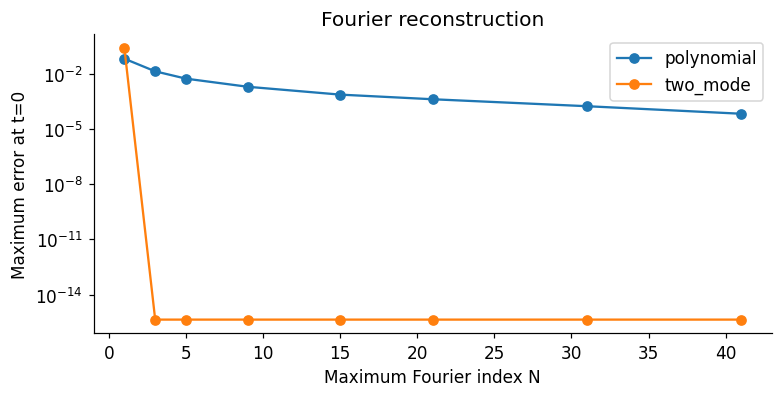

,Fourier index N,t=0.1,t=0.5,t=1
0,15,2.22045e-16,0.0,0.0
1,31,0.00000e+00,0.0,0.0
2,41,0.00000e+00,0.0,0.0


,mode,coefficient
0,"(1,1)",1.00000e+00
1,"(3,3)",2.50000e-01
2,"(1,3)",0.00000e+00
3,"(3,1)",6.93889e-18
4,"(2,2)",-5.55870e-19


,t,maximum two-mode error
0,0.0,4.44089e-16
1,0.1,2.22045e-16
2,0.5,5.55112e-17
3,1.0,2.77556e-17


In [24]:
coordinates = np.linspace(0, 1, 81)
Xa, Ya = np.meshgrid(coordinates, coordinates)
rows = []
for N in (1, 3, 5, 9, 15, 21, 31, 41):
    row = {"Fourier index N": N}
    for case in ("polynomial", "two_mode"):
        row[case] = np.max(np.abs(fourier_solution(Xa,Ya,0,N,case)-initial_condition(Xa,Ya,case)))
    rows.append(row)
reconstruction = pd.DataFrame(rows)
display(reconstruction)
fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
for case in ("polynomial", "two_mode"):
    ax.semilogy(reconstruction.iloc[:,0], np.maximum(reconstruction[case], np.finfo(float).eps), "o-", label=case)
ax.set(xlabel="Maximum Fourier index N", ylabel="Maximum error at t=0", title="Fourier reconstruction")
ax.legend(); plt.show()

positive_rows = []
for N in (15, 31, 41):
    row = {"Fourier index N": N}
    for t in (.1, .5, 1):
        row[f"t={t:g}"] = np.max(np.abs(fourier_solution(Xa,Ya,t,N,"polynomial")-fourier_solution(Xa,Ya,t,63,"polynomial")))
    positive_rows.append(row)
display(pd.DataFrame(positive_rows))
assert np.max(pd.DataFrame(positive_rows).iloc[:,1:].to_numpy()) < 1e-10

# Check the two-mode coefficients independently by numerical quadrature.
q = np.linspace(0,1,501)
Xq, Yq = np.meshgrid(q,q)
integrate = getattr(np, "trapezoid", None)
if integrate is None:
    integrate = np.trapz
coefficients = []
for p,qmode in ((1,1),(3,3),(1,3),(3,1),(2,2)):
    integrand = initial_condition(Xq,Yq,"two_mode")*np.sin(p*np.pi*Xq)*np.sin(qmode*np.pi*Yq)
    value = 4*integrate(integrate(integrand,q,axis=1),q,axis=0)
    expected = {(1,1):1., (3,3):.25}.get((p,qmode),0.)
    assert abs(value-expected) < 1e-10
    coefficients.append({"mode":f"({p},{qmode})", "coefficient":value})
display(pd.DataFrame(coefficients))
verification = pd.DataFrame([
    {"t":t,"maximum two-mode error":np.max(np.abs(fourier_solution(Xa,Ya,t,3,"two_mode")-exact_two_mode(Xa,Ya,t)))}
    for t in (0,.1,.5,1)])
display(verification)
assert verification.iloc[:,1].max() < 1e-12

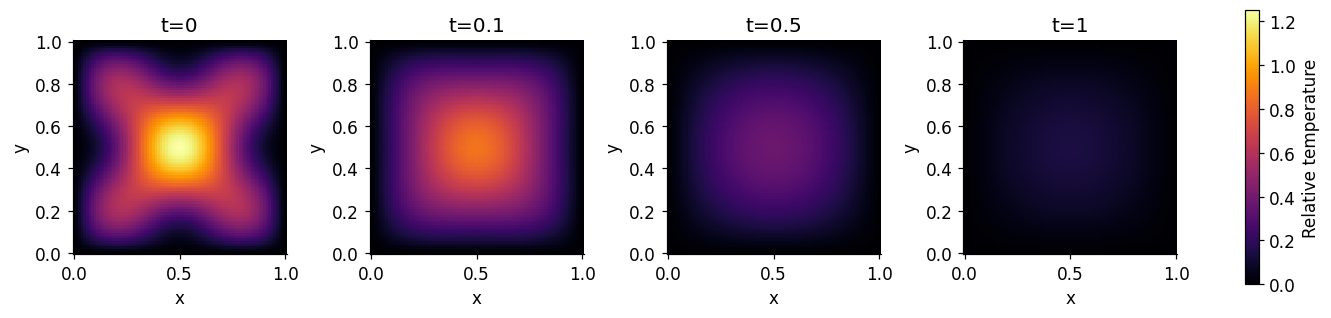

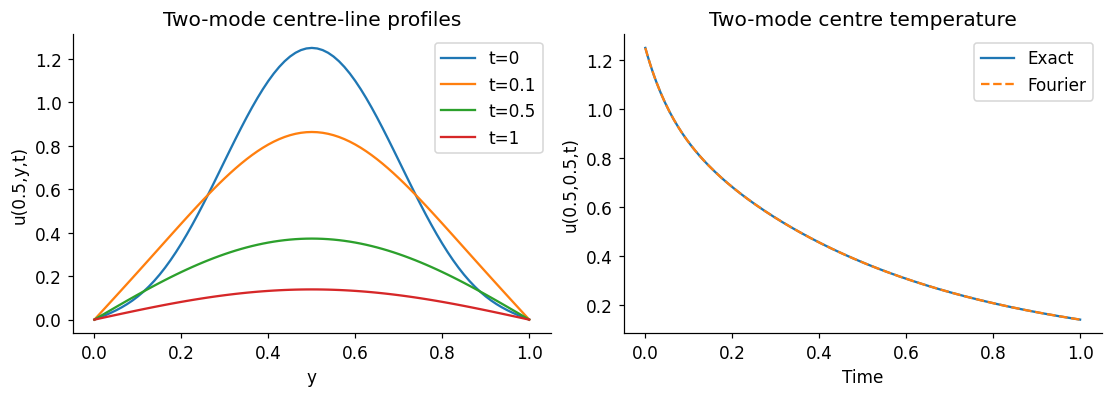

In [25]:
# Report Figures 2–4: two-mode analytical evolution.
plot_times = [0, .1, .5, 1]
fig, axes = plt.subplots(1,4,figsize=(12,3.2),layout="constrained")
for ax,t in zip(axes,plot_times):
    field = fourier_solution(Xa,Ya,t,3,"two_mode")
    im = ax.pcolormesh(coordinates,coordinates,field,shading="auto",cmap="inferno",vmin=0,vmax=1.25)
    ax.set(title=f"t={t:g}",xlabel="x",ylabel="y",aspect="equal")
fig.colorbar(im,ax=axes,label="Relative temperature",shrink=.8)
plt.show()
fig,axes = plt.subplots(1,2,figsize=(10,3.5),layout="constrained")
for t in plot_times:
    axes[0].plot(coordinates,fourier_solution(.5,coordinates,t,3,"two_mode"),label=f"t={t:g}")
axes[0].set(title="Two-mode centre-line profiles",xlabel="y",ylabel="u(0.5,y,t)")
axes[0].legend()
trace_times = np.linspace(0,1,201)
axes[1].plot(trace_times,exact_two_mode(.5,.5,trace_times),label="Exact")
axes[1].plot(trace_times,[float(fourier_solution(.5,.5,t,3,"two_mode")) for t in trace_times],"--",label="Fourier")
axes[1].set(title="Two-mode centre temperature",xlabel="Time",ylabel="u(0.5,0.5,t)")
axes[1].legend(); plt.show()

## 5.2 Cooling and agreement with the reference
Compare the polynomial-profile simulation with the continuous reference at $t=0.1,0.5,1$. Shared temperature scales show cooling; separate difference maps expose the remaining discretization error.

In [26]:
main = simulate(MAIN_M, MAIN_STEPS, keep=True)
h, x, X, Y = grid(MAIN_M)
exact_discrete = modal_reference(MAIN_M, T_FINAL, MAIN_STEPS)
assert l2_error(main["u"], exact_discrete, h) < 1e-8
states = np.array(main["history"]).reshape(-1, MAIN_M, MAIN_M)
assert states.min() > -1e-10
assert np.all(np.diff(np.linalg.norm(states.reshape(MAIN_STEPS+1,-1),axis=1)) <= 1e-10)
print("Final PDE L2 error:", l2_error(main["u"], continuous_reference(x,x,1), h))
print("Final linear-solver L2 error:", l2_error(main["u"], exact_discrete, h))
print("Max relative step residual:", main["max_relative_residual"])

Final PDE L2 error: 0.0007908265870606753
Final linear-solver L2 error: 1.1544937942451187e-12
Max relative step residual: 9.931844401265887e-11


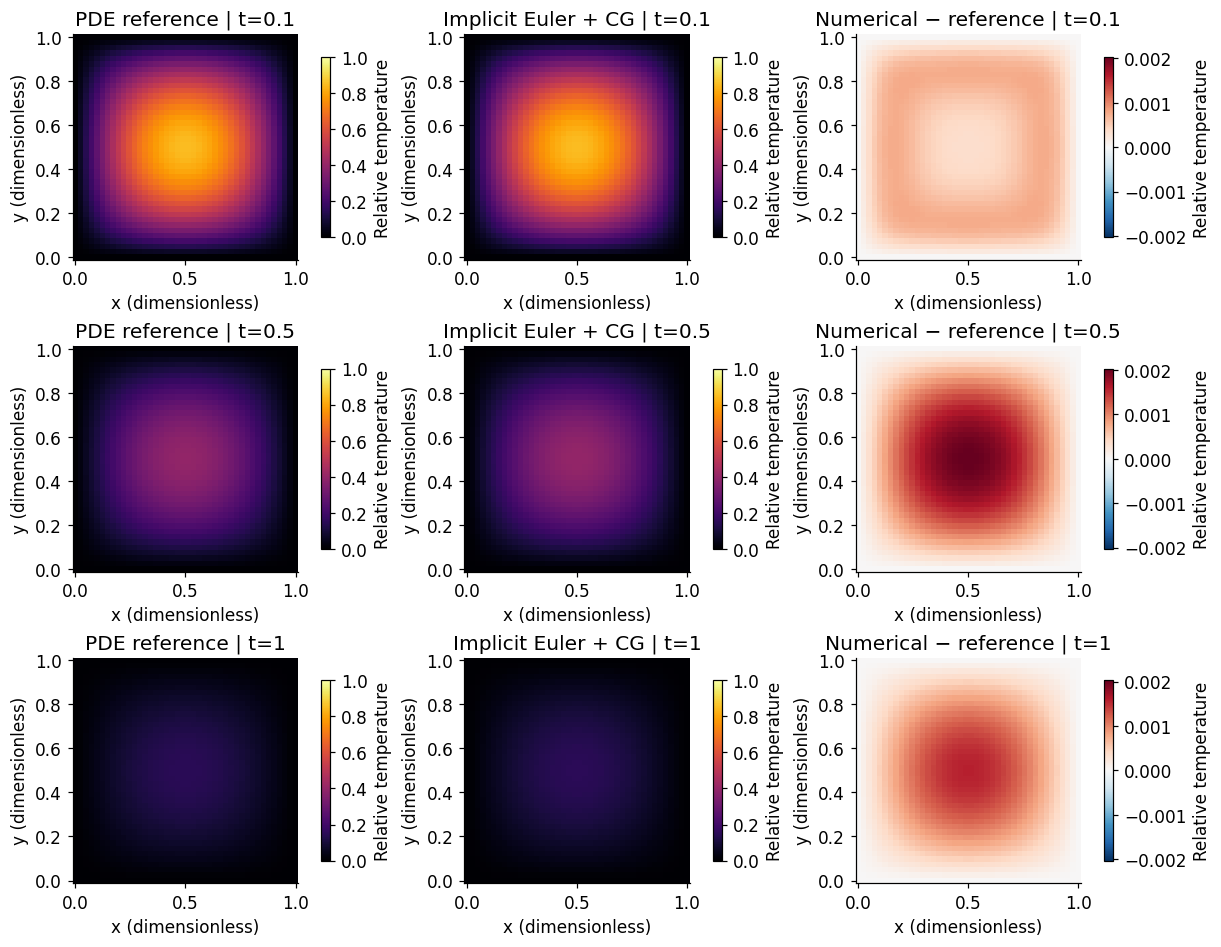

In [27]:
output_times = [0.1, 0.5, 1.0]
full_x = np.r_[0, x, 1]
references = [continuous_reference(x,x,t) for t in output_times]
numerical = [states[round(t*MAIN_STEPS)] for t in output_times]
diffs = [a-b for a,b in zip(numerical,references)]
limit = max(np.max(np.abs(d)) for d in diffs)
fig, axes = plt.subplots(3, 3, figsize=(11, 8.5),
                         layout="constrained")
for row,t in enumerate(output_times):
    for col,field in enumerate([references[row],numerical[row],diffs[row]]):
        padded = np.pad(field,1)
        kwargs = dict(cmap="inferno",vmin=0,vmax=1) if col<2 else dict(cmap="RdBu_r",vmin=-limit,vmax=limit)
        im = axes[row,col].pcolormesh(full_x,full_x,padded,shading="auto",**kwargs)
        axes[row,col].set(title=f"{['PDE reference','Implicit Euler + CG','Numerical − reference'][col]} | t={t:g}",
                          xlabel="x (dimensionless)",ylabel="y (dimensionless)",aspect="equal")
        fig.colorbar(im,ax=axes[row,col],shrink=0.8,label="Relative temperature")
plt.show()

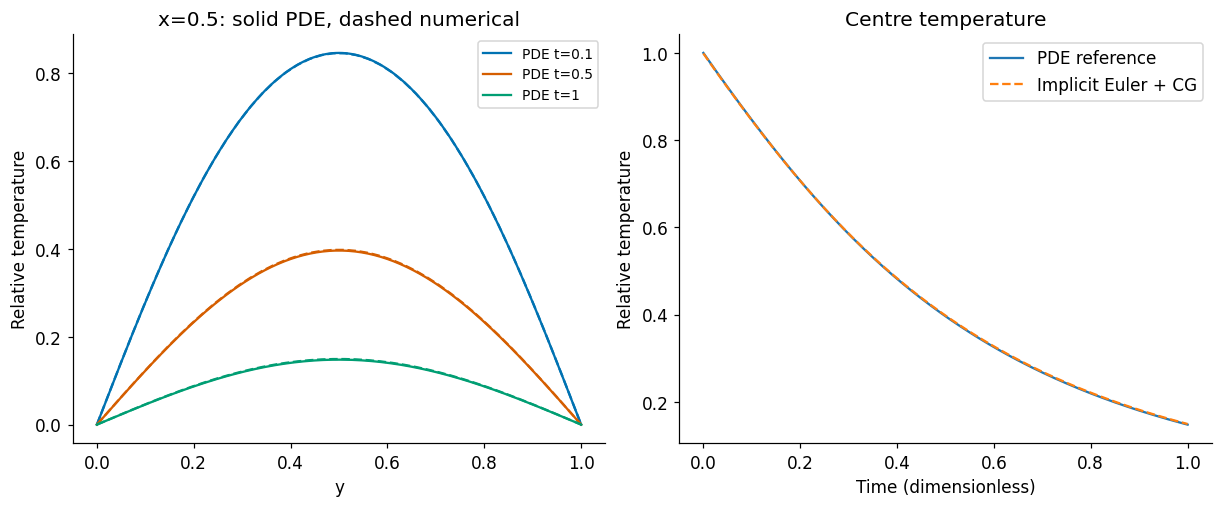

In [28]:
def mid_profile(field):
    m = field.shape[0]
    _, coords, _, _ = grid(m)
    return np.array([np.interp(0.5,coords,row) for row in field])

fig, axes = plt.subplots(1,2,figsize=(11,4.5),layout="constrained")
colors = ["#0072B2","#D55E00","#009E73","#CC79A7"]
yfine = np.linspace(0,1,151)
for t,field,color in zip(output_times,numerical,colors):
    axes[0].plot(yfine,continuous_reference([0.5],yfine,t)[:,0],color=color,label=f"PDE t={t:g}")
    axes[0].plot(full_x,np.r_[0,mid_profile(field),0],"--",color=color)
axes[0].set(title="x=0.5: solid PDE, dashed numerical",xlabel="y",ylabel="Relative temperature")
axes[0].legend(fontsize=9)
times = np.linspace(0,1,MAIN_STEPS+1)
centre = [np.interp(0.5,x,mid_profile(field)) for field in states]
centre_ref = [continuous_reference([0.5],[0.5],t)[0,0] for t in times]
axes[1].plot(times,centre_ref,label="PDE reference")
axes[1].plot(times,centre,"--",label="Implicit Euler + CG")
axes[1].set(title="Centre temperature",xlabel="Time (dimensionless)",ylabel="Relative temperature")
axes[1].legend()
plt.show()

## 5.3 Grid and time-step refinement
Compare $m=10,20,40,80$ with time integration removed to measure spatial order. Then refine $\Delta t$ at fixed $m=40$, using scratch CG and an exact semidiscrete reference to measure temporal order.

Spatial error (time integration removed):


,m,h,L2_error,order
0,10,0.09091,0.00094,NaN
1,20,0.04762,0.00026,2.00446
2,40,0.02439,0.00007,2.00121
3,80,0.01235,0.00002,2.00031


Temporal error (spatial error removed):


,steps,dt,L2_error,order
0,10,0.10000,0.01307,NaN
1,20,0.05000,0.00665,0.97510
2,40,0.02500,0.00335,0.98758
3,80,0.01250,0.00168,0.99381
4,160,0.00625,0.00084,0.99691


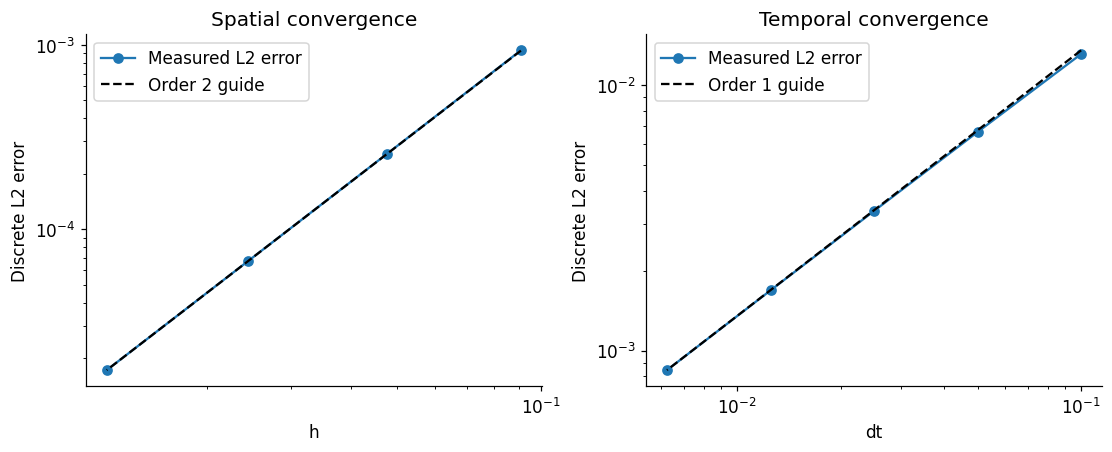

In [29]:
sine = lambda X,Y: np.sin(np.pi*X)*np.sin(np.pi*Y)
space_rows=[]
for m in (10,20,40,80):
    h_s,_,Xs,Ys = grid(m)
    exact = sine(Xs,Ys)*np.exp(-2*KAPPA*np.pi**2)
    semi = modal_reference(m,1,profile=sine)
    space_rows.append({"m":m,"h":h_s,"L2_error":l2_error(semi,exact,h_s)})
space = pd.DataFrame(space_rows)
space["order"] = np.log(space.L2_error.shift()/space.L2_error)/np.log(space.h.shift()/space.h)

time_rows=[]
m_t=40
h_t,_,_,_ = grid(m_t)
semi = modal_reference(m_t,1,profile=sine)
for steps in (10,20,40,80,160):
    result = simulate(m_t,steps,method="scratch",profile=sine)
    time_rows.append({"steps":steps,"dt":1/steps,"L2_error":l2_error(result["u"],semi,h_t)})
temporal = pd.DataFrame(time_rows)
temporal["order"] = np.log(temporal.L2_error.shift()/temporal.L2_error)/np.log(temporal.dt.shift()/temporal.dt)
assert space["order"].iloc[-1] > 1.9
assert temporal["order"].iloc[-1] > 0.95
print("Spatial error (time integration removed):"); display(space)
print("Temporal error (spatial error removed):"); display(temporal)
fig,axes = plt.subplots(1,2,figsize=(10,4),layout="constrained")
for ax,df,col,p,title in [(axes[0],space,"h",2,"Spatial convergence"),
                         (axes[1],temporal,"dt",1,"Temporal convergence")]:
    ax.loglog(df[col],df.L2_error,"o-",label="Measured L2 error")
    ax.loglog(df[col],df.L2_error.iloc[-1]*(df[col]/df[col].iloc[-1])**p,"k--",label=f"Order {p} guide")
    ax.set(title=title,xlabel=col,ylabel="Discrete L2 error")
    ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    ax.legend()
plt.show()

## 5.4 Conditioning and CG convergence
Compare scratch CG with SciPy on the same first-step system. Then vary grid size and time step, and check the response to a small right-hand-side perturbation against the condition-number bound.

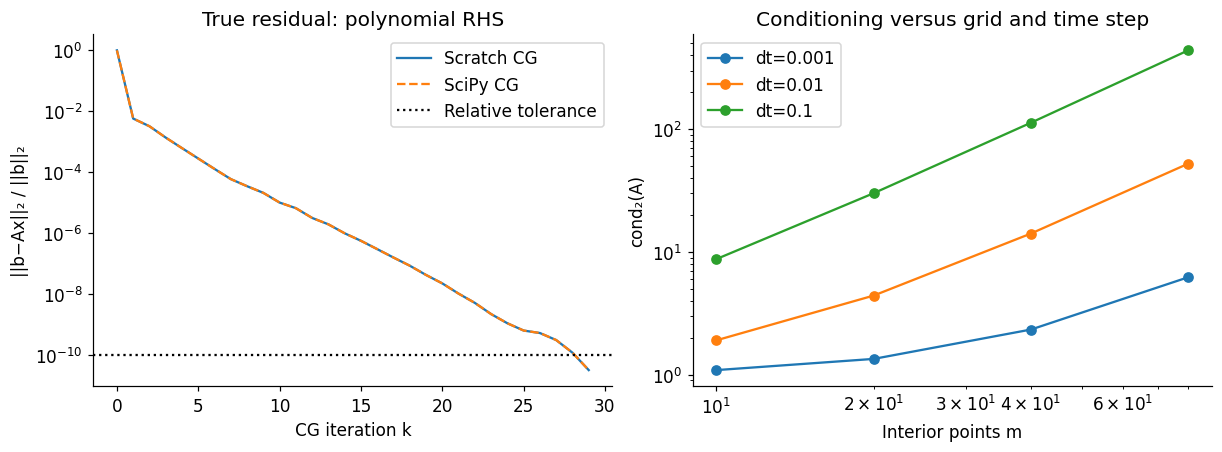

First-step iterations: 29
RHS relative perturbation: 1e-7; solution change: 2.389e-08; bound: 1.415e-06


In [30]:
A = system(MAIN_M, 0.01)
b = initial(X,Y).ravel()
x_cg, info = cg_scratch(A,b,record=True)
scipy_history = [np.linalg.norm(b)]
x_sp, flag = scipy_cg(A,b,rtol=RTOL,atol=ATOL,
    callback=lambda z: scipy_history.append(np.linalg.norm(b-A@z)))
x_lu = splu(A.tocsc()).solve(b)
assert flag == 0 and info["converged"]
assert np.linalg.norm(x_cg-x_lu)/np.linalg.norm(x_lu) < 1e-8
fig,axes = plt.subplots(1,2,figsize=(11,4),layout="constrained")
axes[0].semilogy(np.array(info["history"])/np.linalg.norm(b),label="Scratch CG")
axes[0].semilogy(np.array(scipy_history)/np.linalg.norm(b),"--",label="SciPy CG")
axes[0].axhline(RTOL,color="black",ls=":",label="Relative tolerance")
axes[0].set(title="True residual: polynomial RHS",xlabel="CG iteration k",ylabel="||b−Ax||₂ / ||b||₂")
axes[0].legend()
condition_rows=[]
for dt in (0.001,0.01,0.1):
    values=[]
    for m in (10,20,40,80):
        eig = discrete_eigenvalues(m)
        cond = (1+KAPPA*dt*eig.max())/(1+KAPPA*dt*eig.min())
        values.append(cond)
        condition_rows.append({"m":m,"dt":dt,"condition_A":cond})
    axes[1].loglog([10,20,40,80],values,"o-",label=f"dt={dt:g}")
axes[1].set(title="Conditioning versus grid and time step",xlabel="Interior points m",ylabel="cond₂(A)")
axes[1].legend()
plt.show()
print("First-step iterations:", info["iterations"])
# Sensitivity example: independent deterministic perturbation; bound is worst-case.
rng = np.random.default_rng(SEED)
db = rng.standard_normal(b.size)
db *= 1e-7*np.linalg.norm(b)/np.linalg.norm(db)
factor = splu(A.tocsc())
relative_change = np.linalg.norm(factor.solve(b+db)-x_lu)/np.linalg.norm(x_lu)
eig = discrete_eigenvalues(MAIN_M)
condition = (1+KAPPA*.01*eig.max())/(1+KAPPA*.01*eig.min())
print(f"RHS relative perturbation: 1e-7; solution change: {relative_change:.3e}; bound: {condition*1e-7:.3e}")
assert relative_change <= condition*1e-7 * 1.001

## 5.5 Stopping tolerance
Tighten CG tolerance on the same problem to see when discretization error dominates. The cross-method timing and memory comparison is collected in Section 7.

,rtol,iterations_total,solver_L2,PDE_L2,max_step_relative_residual
0,1.00000e-03,232,7.00489e-05,0.00158,9.98785e-04
1,1.00000e-05,397,7.08407e-07,0.00151,9.96900e-06
2,1.00000e-07,649,2.41732e-09,0.00151,9.81849e-08
3,1.00000e-10,971,2.58691e-12,0.00151,9.85920e-11


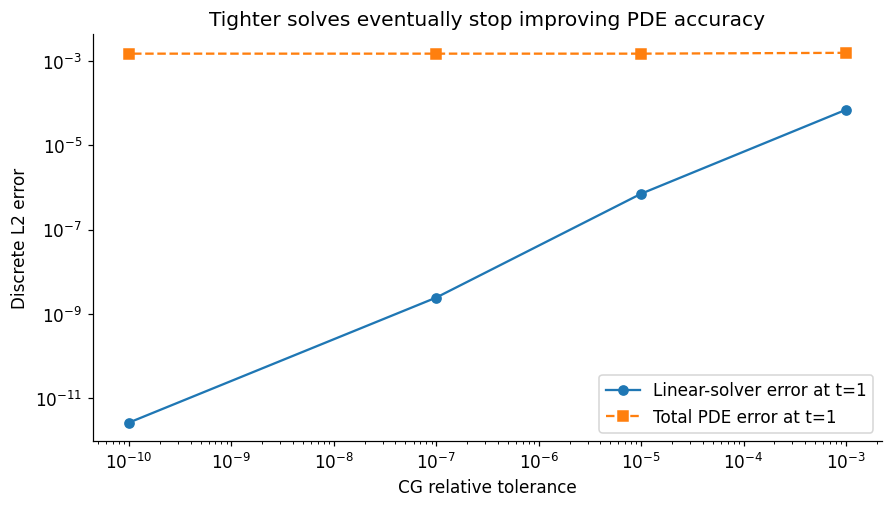

In [31]:
tolerance_rows=[]
h, x, _, _ = grid(MAIN_M)
for tol in (1e-3,1e-5,1e-7,1e-10):
    result=simulate(MAIN_M,100,rtol=tol)
    tolerance_rows.append({"rtol":tol,"iterations_total":result["iterations"].sum(),
        "solver_L2":l2_error(result["u"],modal_reference(MAIN_M,1,100),h),
        "PDE_L2":l2_error(result["u"],continuous_reference(x,x,1),h),
        "max_step_relative_residual":result["max_relative_residual"]})
tolerances=pd.DataFrame(tolerance_rows)
display(tolerances)
fig,ax=plt.subplots(layout="constrained")
ax.loglog(tolerances.rtol,tolerances.solver_L2,"o-",label="Linear-solver error at t=1")
ax.loglog(tolerances.rtol,tolerances.PDE_L2,"s--",label="Total PDE error at t=1")
ax.set(xlabel="CG relative tolerance",ylabel="Discrete L2 error",title="Tighter solves eventually stop improving PDE accuracy")
ax.legend(); plt.show()

## 5.6–6 Resolution choice and conclusions
Finally refine both space and time for the main polynomial profile. These results support a practical resolution choice; timing rankings apply to this machine and these modest grids, not every heat problem.

In [32]:
joint_rows=[]
for m,steps in [(20,100),(40,200),(80,400)]:
    h_j,xj,_,_=grid(m)
    result=simulate(m,steps,method="lu")
    ref=continuous_reference(xj,xj,1)
    joint_rows.append({"m":m,"dt":1/steps,"L2_error":l2_error(result["u"],ref,h_j),
                       "max_error":np.max(np.abs(result["u"]-ref)),"total_s":result["total_s"]})
joint=pd.DataFrame(joint_rows)
display(joint)
assert np.all(np.diff(joint.L2_error)<0)

,m,dt,L2_error,max_error,total_s
0,20,0.0100,0.00171,0.00339,0.02386
1,40,0.0050,0.00079,0.00158,0.07444
2,80,0.0025,0.00038,0.00076,0.24014


## 7. Analytical and numerical methods: time, accuracy and memory
Use the polynomial initial profile on every grid. Numerical methods use the same $\Delta t=0.01$, $T=1$, previous-step initial guess and residual tolerance; LU factors are reused. Fourier evaluation returns the final field directly at the same nodes, with maximum index 31.

**Timing:** setup plus final-field evaluation or all 100 time steps, excluding plotting and error calculations; medians of three trials. **Memory:** sampled peak extra resident memory (MB, baseline after imports), measured separately in a fresh process for each case. It includes matrix/factor storage and work arrays, but excludes plots and trajectories; 1 ms sampling can miss brief peaks, so small differences are approximate.

The worker below keeps timing and memory isolated from the notebook. Requires `psutil` in addition to the existing dependencies.

In [33]:
import json, subprocess, tempfile
from pathlib import Path

# This source is written only to a temporary folder while the comparisons run.
comparison_worker = r'''import sys, json, time, threading, gc
import numpy as np
from scipy import sparse
from scipy.sparse.linalg import cg, splu, spsolve_triangular, LinearOperator
import psutil

KAPPA, DT, STEPS, RTOL, ATOL = .1, .01, 100, 1e-10, 1e-13

def ic0_plate(m, A):
    # IC(0): retain only the diagonal and the two lower stencil diagonals.
    # For this five-point pattern the off-diagonal updates have no common predecessors.
    N = m*m
    a = A.diagonal()
    coupling = KAPPA*DT*(m+1)**2
    d = np.empty(N)
    left, below = np.zeros(N-1), np.zeros(N-m)
    for i in range(N):
        pivot = a[i]
        if i % m:
            value = -coupling/d[i-1]
            left[i-1] = value
            pivot -= value*value
        if i >= m:
            value = -coupling/d[i-m]
            below[i-m] = value
            pivot -= value*value
        if pivot <= 0:
            raise RuntimeError("IC(0) encountered a nonpositive pivot")
        d[i] = np.sqrt(pivot)
    L = sparse.diags([below,left,d],[-m,-1,0],shape=(N,N),format="csr")
    L.eliminate_zeros()
    # Cache the triangular factor's solve structure instead of preparing it each iteration.
    triangular = splu(L.tocsc(),permc_spec="NATURAL",diag_pivot_thresh=0)
    def apply(v):
        z = triangular.solve(v)
        return triangular.solve(z,trans="T")
    return LinearOperator(A.shape,matvec=apply,dtype=float)

def run_case(m, method):
    start = time.perf_counter()
    h = 1/(m+1)
    x = np.arange(1,m+1)*h
    X,Y = np.meshgrid(x,x)
    if method == "Fourier":
        modes = np.arange(1,32,2)
        S = np.sin(np.pi*np.outer(x,modes))
        coefficients = 32/(np.pi*modes)**3
        setup = time.perf_counter()-start
        solve_start = time.perf_counter()
        v = np.sum(S*(coefficients*np.exp(-KAPPA*(np.pi*modes)**2)),axis=1)
        u = np.outer(v,v)
        return dict(u=u,setup_s=setup,solve_s=time.perf_counter()-solve_start,
                    total_s=time.perf_counter()-start,iterations=None,residual=None)
    B = sparse.diags([-np.ones(m-1),2*np.ones(m),-np.ones(m-1)],[-1,0,1],format="csr")
    A = (sparse.eye(m*m,format="csr") + KAPPA*DT/h**2*
         (sparse.kron(sparse.eye(m),B)+sparse.kron(B,sparse.eye(m)))).tocsr()
    u = (16*X*(1-X)*Y*(1-Y)).ravel()
    preconditioner = None
    if method == "LU":
        factor = splu(A.tocsc())
    elif method == "Gauss-Seidel":
        red = np.indices((m,m)).sum(axis=0) % 2 == 0
        coupling = KAPPA*DT/h**2
        diagonal = 1+4*coupling
        padded = np.zeros((m+2,m+2))
    elif method == "IC(0)-CG":
        preconditioner = ic0_plate(m,A)
    setup = time.perf_counter()-start
    total_iterations, maximum_residual = 0,0.
    solve_start = time.perf_counter()
    for step in range(STEPS):
        b = u.copy()
        target = max(ATOL,RTOL*np.linalg.norm(b))
        if method == "LU":
            u = factor.solve(b)
            count = 0
        elif method == "Gauss-Seidel":
            # Red–black Gauss–Seidel: update one colour, then the other.
            # Neighbours have opposite colours, so each colour can be vectorized.
            interior = padded[1:-1,1:-1]
            interior[:] = u.reshape(m,m)
            rhs = b.reshape(m,m)
            for count in range(0,5*m*m+1):
                if np.linalg.norm(b-A@interior.ravel()) <= target:
                    break
                for colour in (red, ~red):
                    neighbours = (padded[:-2,1:-1]+padded[2:,1:-1]+
                                  padded[1:-1,:-2]+padded[1:-1,2:])
                    updated = (rhs+coupling*neighbours)/diagonal
                    interior[colour] = updated[colour]
            else:
                raise RuntimeError("Gauss-Seidel did not converge")
            u = interior.ravel().copy()
        else:
            counter = [0]
            def tick(xk): counter[0] += 1
            u,flag = cg(A,b,x0=u,rtol=RTOL,atol=ATOL,maxiter=5*m*m,
                        M=preconditioner,callback=tick)
            if flag != 0:
                raise RuntimeError(f"{method} failed: {flag}")
            count = counter[0]
        norm = np.linalg.norm(b-A@u)
        if norm > 1.01*target:
            raise RuntimeError(f"Residual check failed: {method}")
        maximum_residual = max(maximum_residual,norm/np.linalg.norm(b))
        total_iterations += count
    solve_time = time.perf_counter()-solve_start
    return dict(u=u.reshape(m,m),setup_s=setup,solve_s=solve_time,
                total_s=time.perf_counter()-start,iterations=total_iterations/STEPS,
                residual=maximum_residual)

def measured_memory(m,method):
    # Dedicated fresh process; sampling is excluded from reported timing trials.
    process = psutil.Process()
    baseline = process.memory_info().rss
    peak = [baseline]
    stop = threading.Event()
    def sample():
        while not stop.is_set():
            peak[0] = max(peak[0],process.memory_info().rss)
            stop.wait(.001)
    thread = threading.Thread(target=sample,daemon=True)
    thread.start()
    try:
        result = run_case(m,method)
        peak[0] = max(peak[0],process.memory_info().rss)
    finally:
        stop.set(); thread.join()
    result["peak_extra_MB"] = max(0,peak[0]-baseline)/1e6
    return result

if __name__ == "__main__":
    m,method,mode = int(sys.argv[1]),sys.argv[2],sys.argv[3]
    if mode == "memory":
        result = measured_memory(m,method)
    else:
        # A tiny warm-up reduces first-call overhead without warming the target grid.
        run_case(4,method)
        gc.collect()
        runs = [run_case(m,method) for _ in range(3)]
        result = runs[-1]
        for key in ("setup_s","solve_s","total_s"):
            result[key] = float(np.median([r[key] for r in runs]))
    result["u"] = result["u"].tolist()
    print(json.dumps(result))
'''

def compare_case(worker_path, m, method):
    results = []
    for mode in ("timing", "memory"):
        completed = subprocess.run(
            [sys.executable, str(worker_path), str(m), method, mode],
            check=True, capture_output=True, text=True)
        results.append(json.loads(completed.stdout))
    timing, memory = results
    u = np.asarray(timing.pop("u"))
    h,coords,_,_ = grid(m)
    reference = continuous_reference(coords,coords,1)
    discrete = modal_reference(m,1,100)
    row = {"Method":method, "m":m,
           "Setup (s)":timing["setup_s"], "Total (s)":timing["total_s"],
           "Peak extra (MB)":memory["peak_extra_MB"],
           "Iterations/step":np.nan if method == "LU" else timing["iterations"],
           "Max rel. residual":timing["residual"],
           "L2 vs PDE ref.":l2_error(u,reference,h),
           "Solver L2":np.nan if method == "Fourier" else l2_error(u,discrete,h)}
    if method != "Fourier":
        assert row["Solver L2"] < 1e-7
    else:
        assert row["L2 vs PDE ref."] < 1e-10
    return row,u,timing["solve_s"]


### 7.1 Four-grid comparison
CG here uses SciPy, already checked against the scratch implementation in Section 5.4. “L2 vs PDE ref.” is total numerical error; for Fourier it is agreement between truncations 31 and 63, not an independently known exact error. “Solver L2” compares with exact discrete implicit Euler and does not apply to Fourier. Gauss–Seidel uses red–black ordering for efficient array updates; its iteration count means full two-colour sweeps.

In [34]:
comparison_rows, comparison_fields = [], {}
large_rows = []
with tempfile.TemporaryDirectory(prefix="plate_comparison_") as temp:
    worker_path = Path(temp)/"worker.py"
    worker_path.write_text(comparison_worker, encoding="utf-8")
    for m in (10,20,40,80):
        for method in ("Fourier","CG","Gauss-Seidel","LU"):
            row,field,_ = compare_case(worker_path,m,method)
            comparison_rows.append(row)
            if m == 80:
                comparison_fields[method] = field
        print(f"Completed m={m} ({m*m:,} unknowns)")
    # A larger system: identical CG implementation with and without IC(0).
    for method in ("CG","IC(0)-CG"):
        row,_,solve_s = compare_case(worker_path,100,method)
        row["Solve (s)"] = solve_s
        large_rows.append(row)
comparison = pd.DataFrame(comparison_rows)
large_comparison = pd.DataFrame(large_rows)

def compact_table(frame):
    formats = {c:"{:.3g}" for c in frame.select_dtypes(include="number").columns if c != "m"}
    return frame.style.format(formats,na_rep="—").hide(axis="index")
# Display the main comparison without the supporting solver-error column.
display(compact_table(comparison.drop(columns="Solver L2")))


Completed m=10 (100 unknowns)
Completed m=20 (400 unknowns)
Completed m=40 (1,600 unknowns)
Completed m=80 (6,400 unknowns)


Method,m,Setup (s),Total (s),Peak extra (MB),Iterations/step,Max rel. residual,L2 vs PDE ref.
Fourier,10,3.99e-05,5.13e-05,0.152,—,—,0
CG,10,0.000944,0.00829,0.463,4,9.22e-11,0.00243
Gauss-Seidel,10,0.001,0.0205,0.492,9,4.82e-11,0.00243
LU,10,0.00116,0.0025,0.987,—,4.07e-16,0.00243
Fourier,20,4.86e-05,6.17e-05,0.152,—,—,0
CG,20,0.00158,0.0159,0.582,5.5,9.89e-11,0.00171
Gauss-Seidel,20,0.00105,0.0598,0.487,22,5.75e-11,0.00171
LU,20,0.0029,0.00757,0.774,—,6.91e-16,0.00171
Fourier,40,4.06e-05,5.79e-05,0.143,—,—,0
CG,40,0.00121,0.0258,0.922,9.71,9.86e-11,0.00151


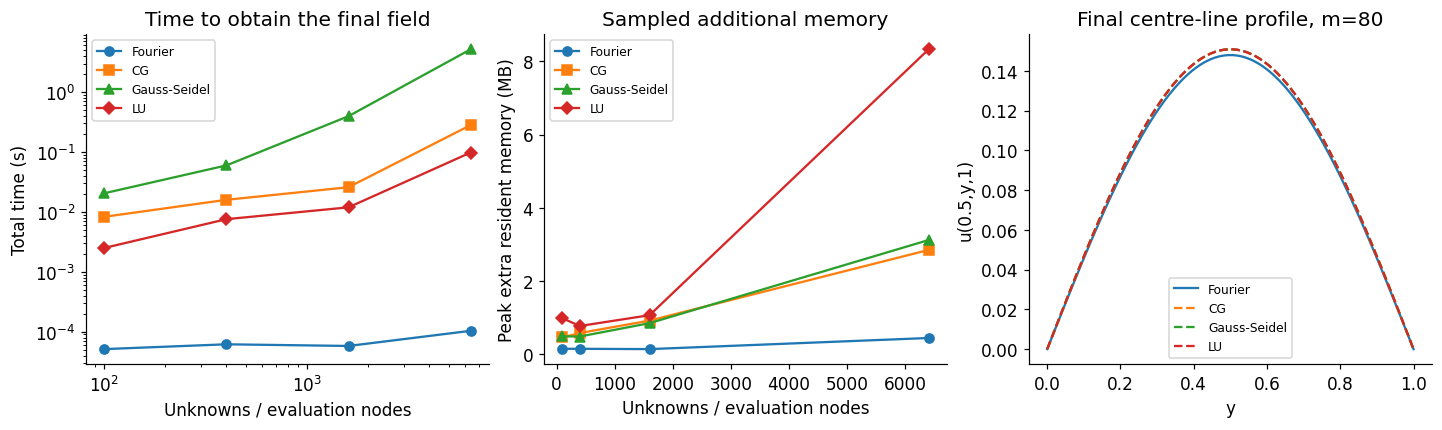

In [35]:
fig,axes = plt.subplots(1,3,figsize=(13,3.8),layout="constrained")
markers = {"Fourier":"o","CG":"s","Gauss-Seidel":"^","LU":"D"}
for method,group in comparison.groupby("Method",sort=False):
    axes[0].loglog(group.m**2,group["Total (s)"],marker=markers[method],label=method)
    axes[1].plot(group.m**2,group["Peak extra (MB)"],marker=markers[method],label=method)
    _,coords,_,_ = grid(80)
    profile = mid_profile(comparison_fields[method])
    axes[2].plot(np.r_[0,coords,1],np.r_[0,profile,0],
                 linestyle="-" if method=="Fourier" else "--",label=method)
axes[0].set(title="Time to obtain the final field",xlabel="Unknowns / evaluation nodes",ylabel="Total time (s)")
axes[1].set(title="Sampled additional memory",xlabel="Unknowns / evaluation nodes",ylabel="Peak extra resident memory (MB)")
axes[2].set(title="Final centre-line profile, m=80",xlabel="y",ylabel="u(0.5,y,1)")
for ax in axes: ax.legend(fontsize=8)
plt.show()


### 7.2 Incomplete Cholesky on 10,000 unknowns
Use $m=100$ and the same tolerance and time step. IC(0) retains the lower five-point stencil pattern, giving $M=LL^T$; its inverse is applied with two triangular solves. Build it once and reuse it for all 100 steps. Setup includes assembly and preconditioner construction; total time includes setup. The triangular solve structure is cached once too; it does not factor the original system matrix.

In [36]:
columns = ["Method","Setup (s)","Solve (s)","Total (s)","Peak extra (MB)",
           "Iterations/step","Max rel. residual","L2 vs PDE ref.","Solver L2"]
display(compact_table(large_comparison[columns]))
# Report exact spectral conditioning for the matrix actually solved.
for m in (10,20,40,80,100):
    eig = discrete_eigenvalues(m)
    print(f"m={m:3d}: cond₂(A)={(1+.1*.01*eig.max())/(1+.1*.01*eig.min()):.2f}")
plain,pre = large_comparison.iloc[0],large_comparison.iloc[1]
speedup = plain["Total (s)"]/pre["Total (s)"]
fastest = comparison[comparison.m==80].sort_values("Total (s)").iloc[0]
display(Markdown(f"""**Takeaway.** At m=80, **{fastest['Method']}** is fastest for the final-field task. At m=100, IC(0) changes mean CG iterations from **{plain['Iterations/step']:.1f}** to **{pre['Iterations/step']:.1f}**; the total-time speedup is **{speedup:.2f}×** ({'a net saving' if speedup>1 else 'no net saving'}). Fewer iterations do not necessarily offset triangular-solve overhead.

Fourier evaluation exploits this separable square-domain model and has no time-stepping error. Numerical methods are more adaptable to complex models, but share the same spatial and temporal error here. Read memory as implementation-dependent sampled process growth, not an exact count of array bytes."""))


Method,Setup (s),Solve (s),Total (s),Peak extra (MB),Iterations/step,Max rel. residual,L2 vs PDE ref.,Solver L2
CG,0.00271,0.421,0.423,3.67,23.7,9.98e-11,0.00145,2.2e-12
IC(0)-CG,0.0178,0.822,0.84,5.07,19.3,1e-10,0.00145,4.64e-12


m= 10: cond₂(A)=1.91
m= 20: cond₂(A)=4.42
m= 40: cond₂(A)=14.15
m= 80: cond₂(A)=52.43
m=100: cond₂(A)=80.99


**Takeaway.** At m=80, **Fourier** is fastest for the final-field task. At m=100, IC(0) changes mean CG iterations from **23.7** to **19.3**; the total-time speedup is **0.50×** (no net saving). Fewer iterations do not necessarily offset triangular-solve overhead.

Fourier evaluation exploits this separable square-domain model and has no time-stepping error. Numerical methods are more adaptable to complex models, but share the same spatial and temporal error here. Read memory as implementation-dependent sampled process growth, not an exact count of array bytes.

## Sources and scope
- Course handout: *Group_Project_Descriptions_NLA_and_PDEs.pdf*, NLA-PDE-2, pp. 5–6.
- Report: *PDEs_NLA_BAM_Project.pdf*, Sections 3–6. This notebook follows its sequence; LU remains an explicit comparison baseline, and the temporal refinement now uses CG as described in the report.
- [SciPy CG](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.linalg.cg.html) and [sparse LU](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.linalg.splu.html).

The forced-heating extension is optional and omitted. This shortened version consolidates duplicate Fourier code and removes general nonzero-boundary machinery; the original notebook retains the extended explanations and checks. Original notebook created with OpenAI Codex assistance; this revision was also prepared with Codex assistance. The group should review and understand the submitted work.
- Benchmark interfaces: [SciPy CG](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.linalg.cg.html), [triangular solves](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.linalg.spsolve_triangular.html), [psutil memory measurement](https://psutil.readthedocs.io/en/latest/#psutil.Process.memory_info). Section 7 implements IC(0) specifically for this five-point matrix.
- [Incomplete Cholesky overview (PETSc)](https://petsc.org/main/manualpages/PC/PCICC/); no PETSc installation is required.